In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volume_binance,trades_binance,volumen_binance,SMA_50_binance,SMA_200_binance,...,volatilidad_200_dxy,momentum_50_dxy,momentum_200_dxy,var_diaria_dxy,rango_dia_dxy,RSI_dxy,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
0,2023-01-15,20952.76,21050.74,20551.01,20871.50,178542.22549,5194354.0,3.726444e+09,17185.4972,19521.37485,...,3.000466,-3.905001,-2.815002,0.046457,0.639999,32.663327,NaN,0,NaN,0
1,2023-01-16,20872.99,21474.05,20611.48,21185.65,293078.08262,6856434.0,6.209050e+09,17280.6346,19527.59205,...,3.017310,-4.097501,-2.347504,0.046435,0.629997,29.806200,NaN,0,NaN,0
2,2023-01-17,21185.65,21647.45,20841.31,21134.81,275407.74409,6440138.0,5.820690e+09,17379.0726,19536.86710,...,3.035734,-4.290001,-2.750000,0.046413,0.619995,26.695871,NaN,0,NaN,0
3,2023-01-18,21132.29,21650.00,20407.15,20677.47,350916.01949,7617173.0,7.256055e+09,17463.7714,19543.99040,...,3.055632,-4.459999,-3.119999,-0.029299,1.370003,28.175536,NaN,0,NaN,0
4,2023-01-19,20677.47,21192.00,20659.19,21071.59,251385.84925,5819932.0,5.297100e+09,17541.9304,19552.76920,...,3.079212,-3.889999,-3.760002,-0.293086,0.490005,11.197913,NaN,0,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
797,2025-03-22,84088.79,84539.17,83625.10,83840.59,5420.22114,864481.0,4.544345e+08,90777.9328,84763.04860,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,NaN,0,NaN,0
798,2025-03-23,83840.59,86129.64,83809.75,86082.50,8461.97813,1206533.0,7.284282e+08,90486.8698,84903.60660,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,NaN,0,NaN,0
799,2025-03-24,86082.50,88765.43,85519.09,88191.85,27487.06073,2668191.0,2.424135e+09,90296.6950,85063.66585,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,NaN,0,NaN,0
800,2025-03-24,86082.50,88765.43,85519.09,88191.85,27487.06073,2668191.0,2.424135e+09,90296.6950,85063.66585,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,NaN,0,NaN,0


# Visualización de la variable respuesta (7 días)

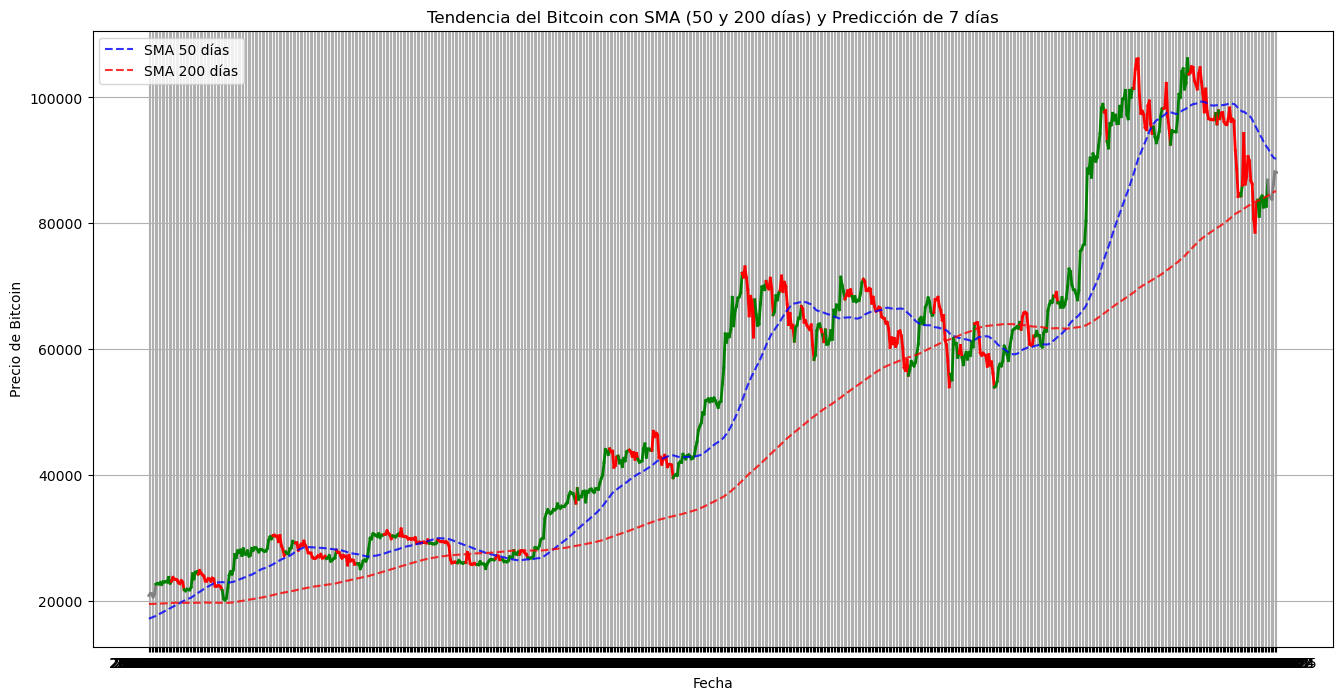

In [3]:
# Crear una visualización donde la línea de "close_binance" cambie de color según la tendencia futura
# Agregando un color adicional para la tendencia neutral

df_plot = df
# Configurar la figura
plt.figure(figsize=(16, 8))

# Recorrer el dataset para cambiar el color del precio de cierre según la tendencia
for i in range(1, len(df_plot)):
    if df_plot.iloc[i]['tendencia_futura_7d'] == 1:
        color = 'green'  # Alcista
    elif df_plot.iloc[i]['tendencia_futura_7d'] == -1:
        color = 'red'  # Bajista
    else:
        color = 'gray'  # Neutral

    plt.plot(df_plot['timestamp'].iloc[i-1:i+1], df_plot['close_binance'].iloc[i-1:i+1], color=color, linewidth=2)

# Graficar las medias móviles
plt.plot(df_plot['timestamp'], df_plot['SMA_50_binance'], label="SMA 50 días", linestyle="dashed", color="blue", alpha=0.8)
plt.plot(df_plot['timestamp'], df_plot['SMA_200_binance'], label="SMA 200 días", linestyle="dashed", color="red", alpha=0.8)

# Configuración de la gráfica
plt.xlabel("Fecha")
plt.ylabel("Precio de Bitcoin")
plt.title("Tendencia del Bitcoin con SMA (50 y 200 días) y Predicción de 7 días")
plt.legend()
plt.grid()

# Mostrar la gráfica mejorada con colores en la línea de precio
plt.show()

# Correlacion con variable respuesta

In [4]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volume_binance', 'trades_binance',
                 'Close_sp500', 'High_sp500', 'Low_sp500', 'Open_sp500', 'Volume_sp500',
                 'Close_nasdaq', 'High_nasdaq', 'Low_nasdaq', 'Open_nasdaq', 'Volume_nasdaq',
                 'Close_dxy', 'High_dxy', 'Low_dxy', 'Open_dxy', 'pct_cambio_7d', 'pct_cambio_30d']].dropna().corr(method='pearson')

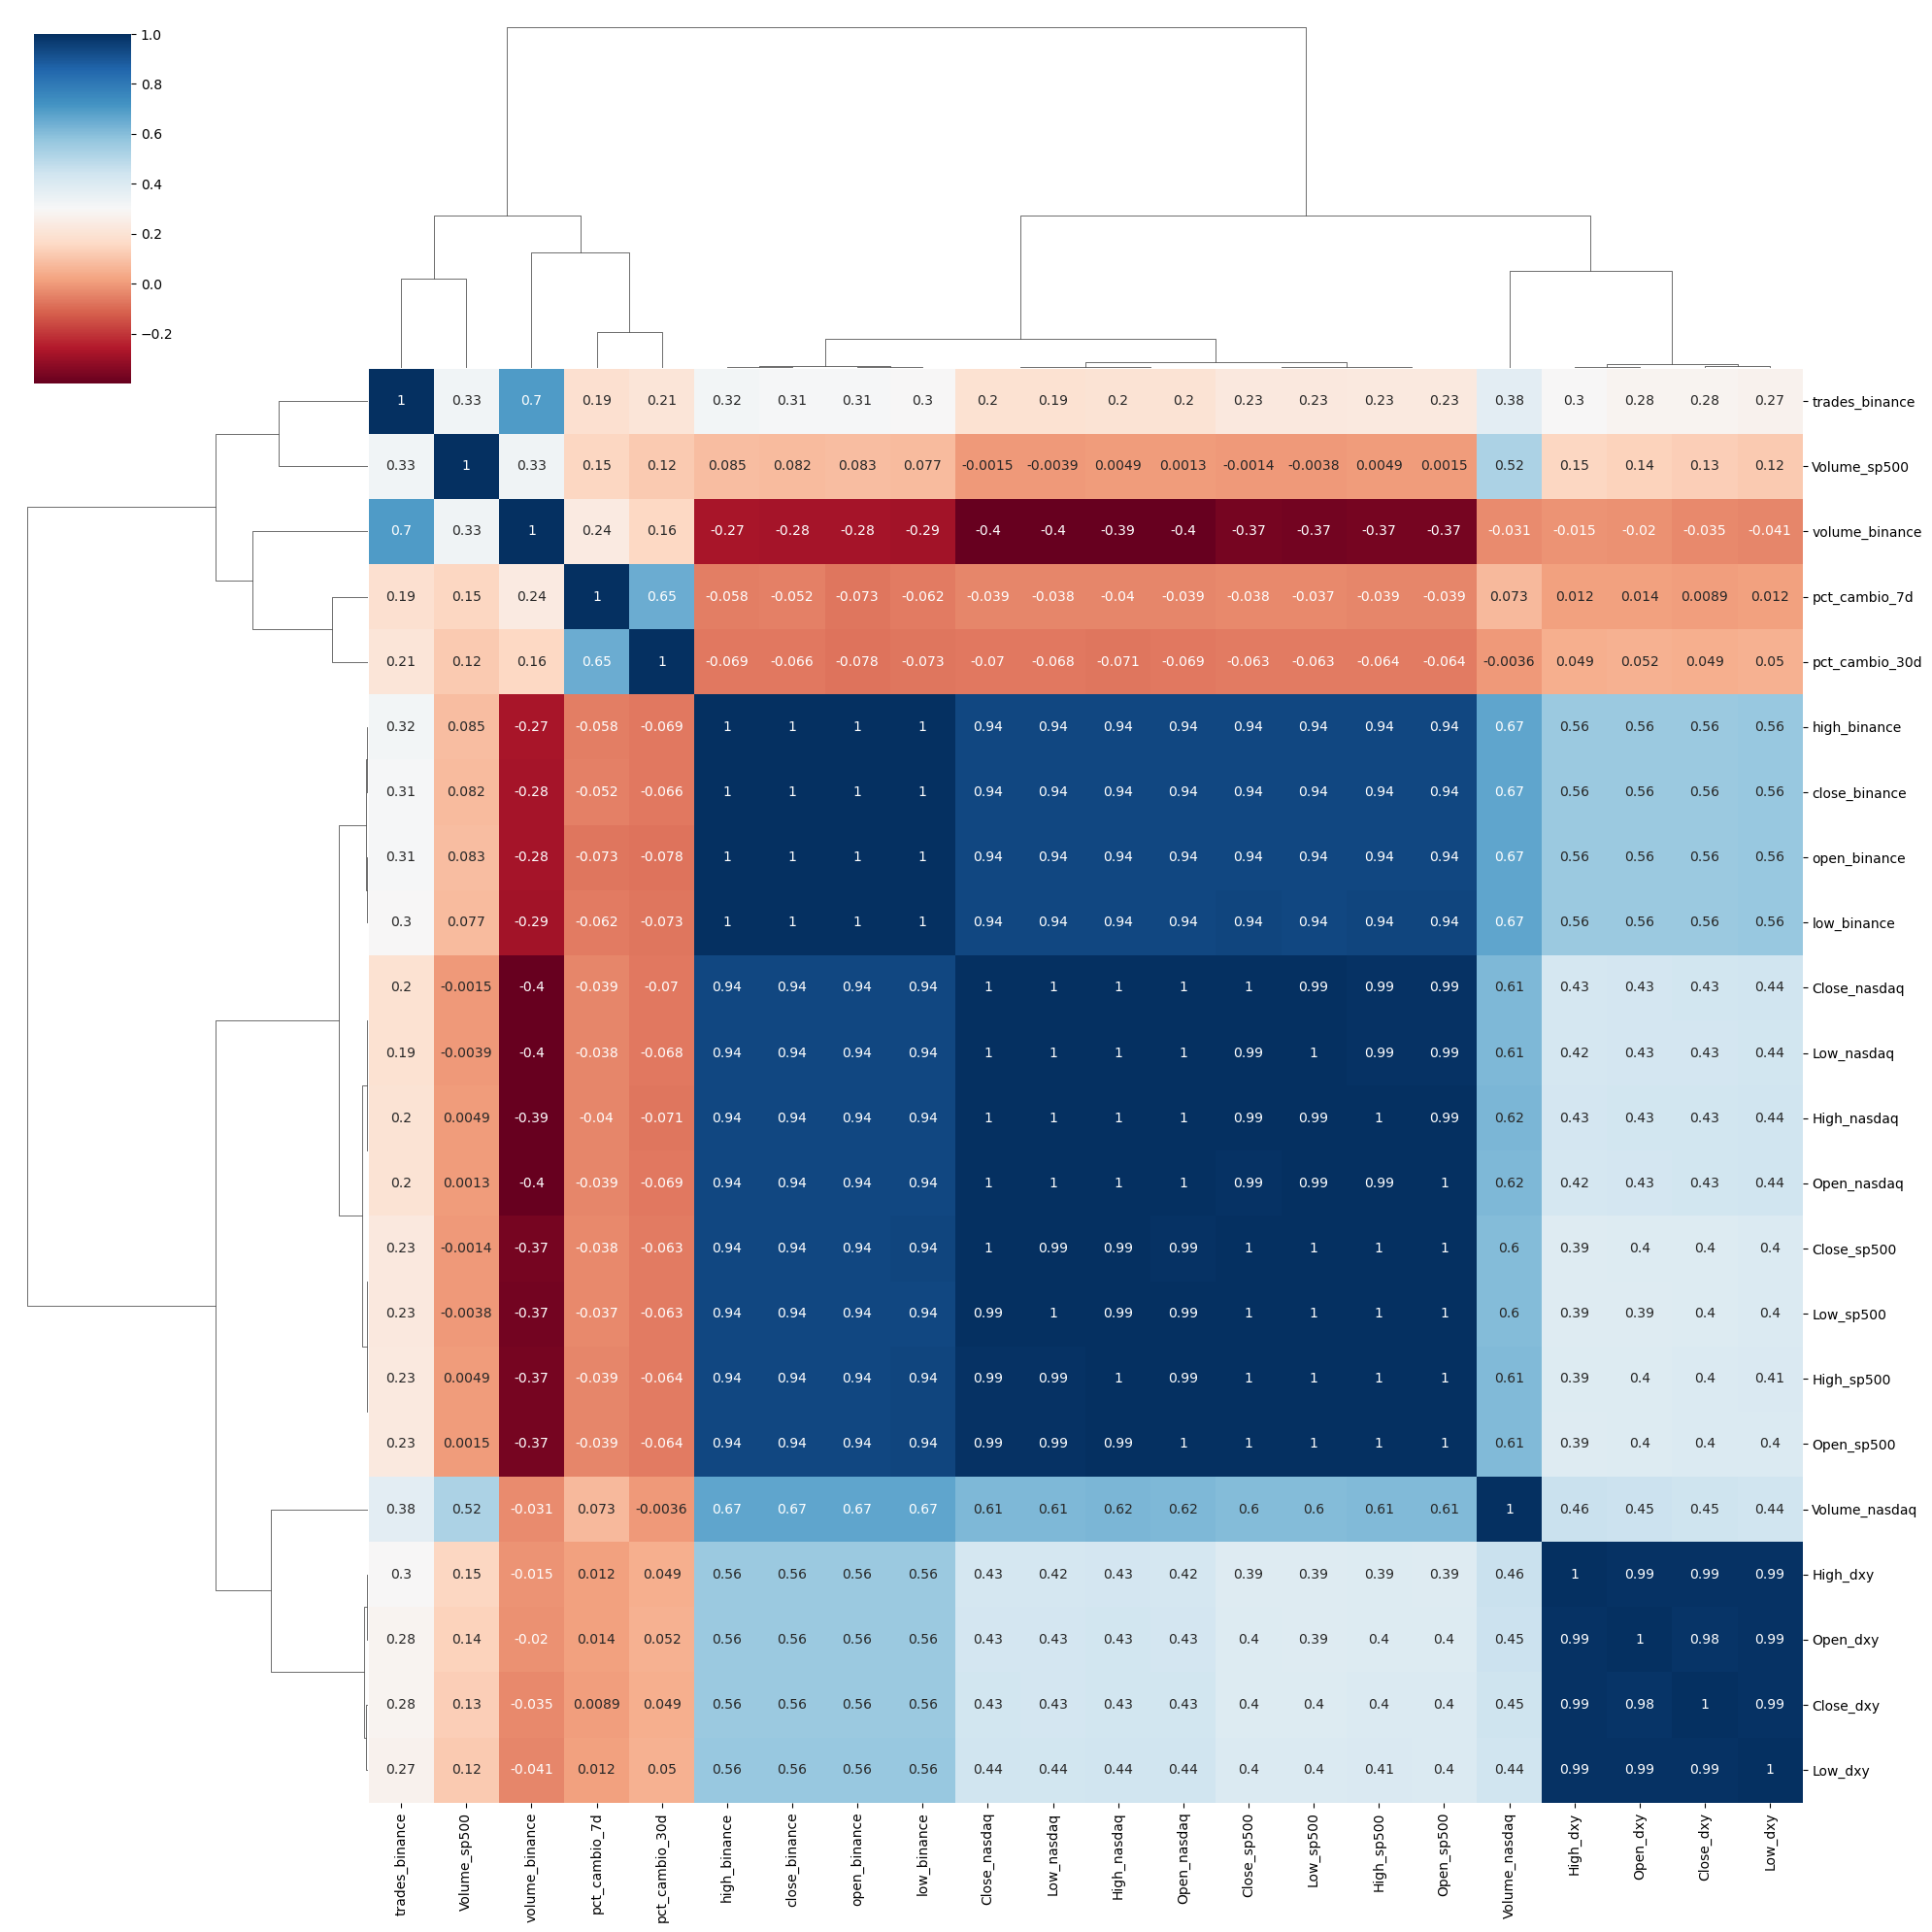

In [5]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()